# Part A

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from sklearn.linear_model import LinearRegression

# 1. Data Cleaning

## Loading and renaming columns

In [2]:
raw_data = pd.read_csv("data/26Ex_Hubble1_UTF8.csv")
hubble1_df = raw_data.copy() # Preserving original data
 
hubble1_df = hubble1_df.dropna(axis=1, how="all") # Drops comma columns whilst verifying that they're empty

name_map = {"Object": "object", "Distance [Mpc]": "d_mpc", "Velocity, cz [km s-1]": "v_kms"} # Changing to briefer names

hubble1_df = hubble1_df.rename(columns=name_map)

hubble1_df["object"] = hubble1_df["object"].str.strip() # Removes blank spaces from some of the names

## Checking for null and invalid values

In [3]:
hubble1_df["d_mpc"] = pd.to_numeric(hubble1_df["d_mpc"], errors="raise")
hubble1_df["v_kms"] = pd.to_numeric(hubble1_df["v_kms"], errors="raise") # Converting both columns to numeric. Any text hidden in the data will raise an error

speed_of_light = 299792.458 # Speed of light in km s^-1

assert hubble1_df["d_mpc"].notna().all(), "Dataset contains NaN distances"
assert hubble1_df["v_kms"].notna().all(), "Dataset contains NaN velocities"
assert (hubble1_df["d_mpc"] > 0).all(), "Dataset contains non positive distances"
assert (hubble1_df["v_kms"] > 0).all(), "Dataset contains non positive velocities"
assert (hubble1_df["v_kms"] < speed_of_light).all(), "Dataset contains speeds faster than the speed of light"

## Checking for duplicates

In [4]:
assert not hubble1_df["object"].duplicated().any(), "Dataset contains duplicate objects" 

duplicate_rows = hubble1_df[hubble1_df.duplicated(subset=["d_mpc", "v_kms"], keep=False)] # Checking for duplicate rows

print(duplicate_rows)

              object  d_mpc     v_kms
11  SDSS-II SN 15101  642.0  48866.17
46  SDSS-II SN 18917  642.0  48866.17


Given that these two rows have the same values to the same precision it seems like a data point has been duplicated. To account for this the second data point will be removed. While this may result in an incorrect label, the data itself appears valid so this will not negatively impact the analysis.

In [5]:
hubble1_df = hubble1_df[hubble1_df["object"] != "SDSS-II SN 18917"].copy()

In [6]:
duplicate_rows = hubble1_df[hubble1_df.duplicated(subset=["v_kms"], keep=False)] # Checking for duplicate velocities

print(duplicate_rows)

                      object   d_mpc     v_kms
15  SDSS J223410.00+000317.9  805.00  63825.81
20  SDSS J030643.76-004514.6  715.00  63825.81
61                  NGC 4321   15.21   1350.00
63                 NGC 4496A   14.86   1350.00
64                  NGC 4535   15.78   1350.00
65                  NGC 4536   14.93   1350.00
66                  NGC 4548   16.22   1350.00
67                  NGC 4639   21.98   1350.00


The two SDSS objects have an identical velocity to seven figures. This appears to be a transcription / duplication error. Given that it is not clear that there is a link between these values that could explain this, they will be omitted from the final calculations. This is a trade off as either value may have been correct.

The duplicate readings for the six NGC objects refer to the same cluster (Virgo) so this velocity is likely the mean of that cluster. These results will hence be included in the final analysis.

In [7]:
hubble1_df = hubble1_df[~hubble1_df["object"].isin(["SDSS J223410.00+000317.9", "SDSS J030643.76-004514.6"])].copy()

In [8]:
duplicate_rows = hubble1_df[hubble1_df.duplicated(subset=["d_mpc"], keep=False)] # Checking for duplicate distances

print(duplicate_rows) # No duplicate distances

hubble1_df.to_csv("data/26Ex_Hubble1_Cleaned.csv", index=False) # Saving the final cleaned data

Empty DataFrame
Columns: [object, d_mpc, v_kms]
Index: []


Finally, the NGC data points will be labelled

In [9]:
hubble1_df["ngc_data"] = hubble1_df["object"].str.startswith("NGC") # Gives a bool true or false

# 2. Analysis

## Methodology:
1. The two datasets will be fitted with a linear regression algorithm. This fit will then be assessed through the use of the R² and RMSE metrics. R² is a unitless metric which is the fraction of the variation of the velocity (in this case) that the fitted line explains. Due to its unitless nature it can be a useful tool for comparing datasets with vastly different values (e.g. a dataset with high velocities and one with low velocities). RMSE is reflective of the typical gap between a data point and the fitted line. 
Its units in this case are in those of the velocity. This can be useful as it allows you to compare the RMSE directly to known physical effects.

2. Residual plots will also be used to assess the fits. A residual plot is a graph of the vertical distance from each point to the fitted line. This can be useful in determining whether a linear fit is appropriate. A good residual plot is one centred on zero with no obvious pattern. Any trend, for example a curve, in the plot may suggest that a linear fit is inappropriate

The following cell defines functions that will help with plotting and data analysis

In [10]:
def fit_hubble(df):
    X = df[["d_mpc"]]
    y = df["v_kms"]

    model = LinearRegression(fit_intercept=False) # Should be no intercept as none in v = H0 * d
    model.fit(X, y)

    H0 = model.coef_[0]
    residuals = y - model.predict(X) # Residual plots can show how close a fitted line is to the data

    n = len(y)
    rss = (residuals**2).sum()
    rmse = np.sqrt(rss / n)
    rse = np.sqrt(rss / (n - 1))
    r2 = model.score(X, y) # RMSE and R2 will all be helpful for the analysis.

    se = rse / np.sqrt((df["d_mpc"] ** 2).sum()) # Gives the standard error for the H0 reading

    rel_rmse = rmse / y.mean()

    return {"H0": H0, "residuals":residuals, "r2":r2, "rmse": rmse, "se":se, "rel_rmse": rel_rmse}

def hubble_plot(df, fit, title, colour="blue"):
    fig, ax = plt.subplots(figsize=(7, 5))
    ax.scatter(df["d_mpc"], df["v_kms"], color=colour)

    d = np.linspace(0, df["d_mpc"].max(), 100)
    ax.plot(d, fit["H0"] * d, color="black", linestyle="--", label="Fitted line") # Uses the fitted H0 to make a line plot on top

    ax.plot([], [], " ", label=f"H$_0$ = {fit['H0']:.2f} $\\pm$ {fit['se']:.2f} km s$^{{-1}}$ Mpc$^{{-1}}$")
    ax.plot([], [], " ", label=f"R$^2$ = {fit['r2']:.3f}")
    ax.plot([], [], " ", label=f"RMSE = {fit['rmse']:.0f} km s$^{{-1}}$")
    ax.plot([], [], " ", label=f"Relative RMSE = {fit['rel_rmse']:.3f}")
    
    ax.set_xlabel("Distance [Mpc]")
    ax.set_ylabel("Velocity, cz [km s$^{-1}$]")
    if title: ax.set_title(title)

    ax.legend()
    plt.show()

def residual_plot(df, fit, title, colour="blue"):
    fig, ax = plt.subplots(figsize=(7, 4))
    ax.scatter(df["d_mpc"], fit["residuals"], color=colour)
    ax.axhline(0, color="black", linestyle="--") # Residuals are a measure of distance from expected, so closeness to 0 suggests the point was accurately predicted

    ax.set_xlabel("Distance [Mpc]")
    ax.set_ylabel("Residual [km s$^{-1}$]")
    if title: ax.set_title(title)

    plt.show()

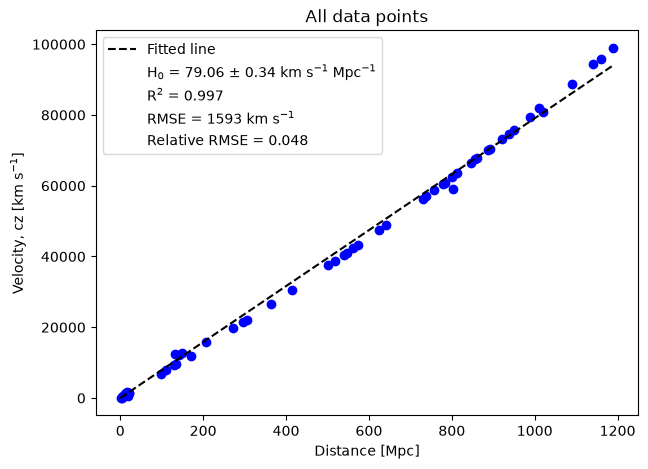

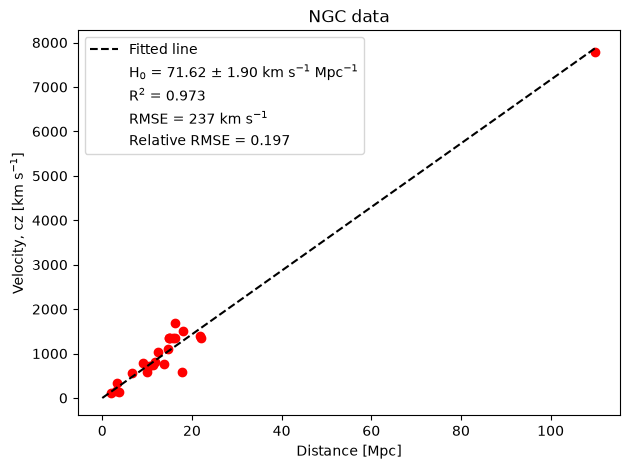

In [11]:
all_data = hubble1_df.copy()
ngc_data = hubble1_df[hubble1_df["ngc_data"]].copy()

all_fit = fit_hubble(all_data)
ngc_fit = fit_hubble(ngc_data)

hubble_plot(all_data, fit=all_fit, title="All data points", colour="blue")
hubble_plot(ngc_data, fit=ngc_fit, title="NGC data", colour="red")

## For all data:
* The data shows a positive linear trend consistent with a line through the origin, supporting the v = H₀d model. 
* The data curves slightly relative to the line, sitting below it from 300-800 Mpc and above it beyond 1000 Mpc. v = cz is a first order approximation, valid for z ≲ 0.1, so the values around z ≈ 0.33 are expected to deviate from the linear model. This will be examined further through the residual plots.
* The absolute scatter for all the data is greater than for the nearer NGC data (RMSE = 1590 km s⁻¹ vs RMSE = 240 km s⁻¹). The greater velocities for the far data however result in this being a smaller relative error.
* The H₀ value of 79.06 ± 0.34 km s⁻¹ Mpc⁻¹ is above the accepted range of 67–74 km s⁻¹ Mpc⁻¹ [1]. It will be compared to literature values in Part B.
* It is worth noting that the SE calculation assumes the error is random, whereas the data appears to have a systematic curve. This will be explored further.

## For the NGC data:
* The data again appears linear and is consistent with a line through the origin. The fit gives H₀ = 71.62 ± 1.90 km s⁻¹ Mpc⁻¹, falling within the previously mentioned range for H₀.
* All but one data point lie within 25 Mpc. This far point may set the slope and inflate the R² value (as the line passes almost directly through it). Therefore this plot should be repeated without it.

[1] E. Di Valentino et al., “In the realm of the Hubble tension—a review of solutions,” Class. Quantum Grav., vol. 38, no. 15, 2021, doi: 10.1088/1361-6382/ac086d.

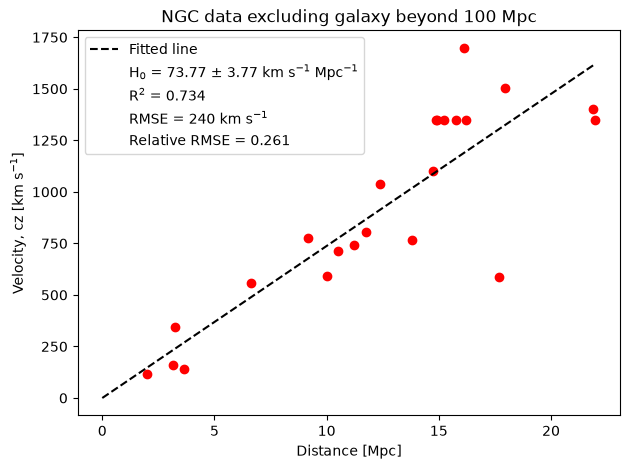

In [12]:
trimmed_ngc_data = ngc_data[ngc_data["d_mpc"] < 25].copy()

trimmed_ngc_fit = fit_hubble(trimmed_ngc_data)
hubble_plot(trimmed_ngc_data, fit=trimmed_ngc_fit, title="NGC data excluding galaxy beyond 100 Mpc", colour="red")

## For the NGC data without the far data point:
* Removing the far galaxy only increases H₀ slightly to 73.77 ± 3.77 km s⁻¹ Mpc⁻¹. Furthermore, the original H₀ value for this data falls within the trimmed data's SE range.
* Removing the point causes the SE to almost double. The R² also falls from 0.973 to 0.734. This suggests that the far point only causes an overstated precision and goodness of fit. This point will be included in further analysis, with this caveat noted.
* These nearby galaxies have heavy scatter around the line (RMSE = 240 km s⁻¹). This is consistent with local gravitational interactions having a greater relative impact on velocity.

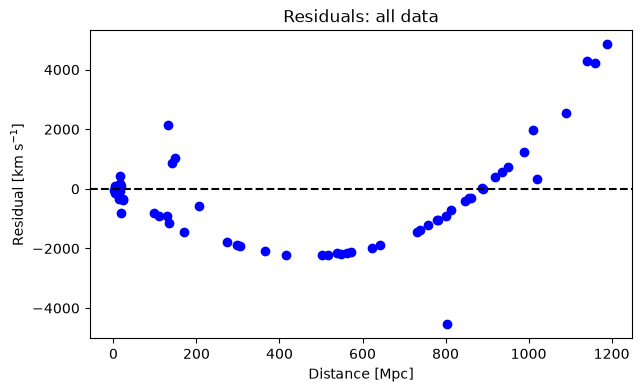

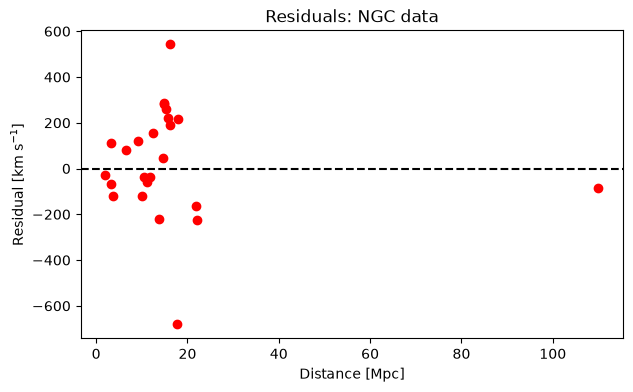

In [13]:
residual_plot(all_data, all_fit, "Residuals: all data", colour="blue")
residual_plot(ngc_data, ngc_fit, "Residuals: NGC data", colour="red")

## For all data:
* The residuals form a clear curve rather than random scatter. This matches the behaviour discussed for the Hubble plot.
* This deviation is therefore systematic. The sharp increase beyond 1000 Mpc also suggests that the v = H₀d model is inadequate for distant galaxies. As a result the SE on the H₀ is likely an underestimate, since it only captures random error.

## For the NGC data:
* The residuals scatter randomly about zero with no clear trend with distance, indicating that a linear model is appropriate for these readings.
* The far galaxy has a small residual of less than 100 km s⁻¹ in magnitude. This confirms that the fit passes very close to this data point, skewing the precision metrics.

# 3. Subset Comparison

* The all data model gives H₀ = 79.06 ± 0.34 km s⁻¹ Mpc⁻¹ compared to H₀ = 71.62 ± 1.90 km s⁻¹ Mpc⁻¹ for the NGC data. Neither value falls within the other's SE range, suggesting that the datasets disagree on the overall behaviour.
* The all data model is more precise (SE = 0.34 km s⁻¹ Mpc⁻¹ vs 1.90 km s⁻¹ Mpc⁻¹) but its residuals show that the fit exhibits systematic error and that the fit fails for large distances.
* The NGC residuals are randomly distributed so a linear fit is more appropriate, but the data is less precise.
* Overall, despite the NGC reading having less precision it is the more trustworthy value for the H₀ reading as it doesn't display the systematic issues the all data model shows. Furthermore, the true uncertainty in the all data model will be greater than the SE we have calculated. However, as shown by the trimmed fit, the NGC SE is itself understated by the far galaxy.

In [14]:
fits = {"all": (all_data, all_fit), "ngc": (ngc_data, ngc_fit), "ngc_trimmed": (trimmed_ngc_data, trimmed_ngc_fit)}

results_df = pd.DataFrame([{"subset": name, "H0": round(fit["H0"], 2), "se": round(fit["se"], 2), "r2": round(fit["r2"], 3), "rmse": round(fit["rmse"], 2)} for name, (df, fit) in fits.items()])

results_df.to_csv("data/Hubble1_Results.csv", index=False) # Saving the Part A results to load into Part B